# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

**Question.** A taxi (matatu) association runs 14-seater vehicles on three routes out of Kampala. It wants to (1) understand fares through a supply-demand model,
(2) forecast next-day demand and revenue, and (3) decide how many vehicles to deploy. Logic lives in `src/taxi.py`.

*The Ntinda passenger counts come from the original question; the other routes are illustrative.*

In [ ]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))          # so that `from src.xxx import ...` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                              # fixed seed -> Restart & Run All is reproducible
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

import copy
from scipy import linalg
from src.taxi import (ROUTES, Route, equilibrium, market_position, Forecaster, MovingAverageForecaster,
                      ExponentialSmoothingForecaster, LinearTrendForecaster, SeasonalNaiveForecaster,
                      rolling_origin_mae, tune_alpha, backtest_table, best_model_for, vehicles_needed,
                      simulate_weekly_series)

: 

## Task 1 - The `Route` class

In [2]:
routes = [Route(n, p, f) for n, (p, f) in ROUTES.items()]
print(routes)
rows = []
for r in routes:
    s = r.describe()
    rows.append({"route": r.name, "fare (UGX)": r.fare, "mean pax/day": s["mean"], "variance": s["variance"], "st.dev": s["stdev"],
                 "total revenue 10 d (UGX)": r.total_revenue(), "mean daily revenue (UGX)": r.daily_revenue().mean()})
display(pd.DataFrame(rows).set_index("route").round(1))
print("Ntinda daily revenue (UGX):", routes[0].daily_revenue().astype(int).tolist())

[Route('Kampala-Ntinda', days=10, fare=2000), Route('Kampala-Entebbe', days=10, fare=5000), Route('Kampala-Mukono', days=10, fare=3000)]


,fare (UGX),mean pax/day,variance,st.dev,total revenue 10 d (UGX),mean daily revenue (UGX)
route,,,,,,
Kampala-Ntinda,"2,000.000",47.400,54.300,7.400,"948,000.000","94,800.000"
Kampala-Entebbe,"5,000.000",67.800,45.100,6.700,"3,390,000.000","339,000.000"
Kampala-Mukono,"3,000.000",52.000,26.400,5.100,"1,560,000.000","156,000.000"


Ntinda daily revenue (UGX): [70000, 80000, 84000, 100000, 110000, 120000, 96000, 104000, 94000, 90000]


Entebbe has the highest revenue (about UGX 340,000 a day) because of its fare (UGX 5,000) as well as its volume, while Ntinda carries fewer passengers at a lower fare. Ntinda's coefficient of variation
(about 0.16) is the highest of the three, so its passenger counts are the least predictable.

## Task 2 - Supply-demand equilibrium for Ntinda (2x2 linear system)

Demand: Q = 120 - 0.02 P. Supply: Q = 10 + 0.03 P. Move the unknowns (P, Q) to the left-hand side:

- 0.02 P + Q = 120
- -0.03 P + Q = 10

which is A [P, Q]^T = b with A = [[0.02, 1], [-0.03, 1]] and b = [120, 10].

det(A) = 0.050  (non-zero -> unique equilibrium)
Equilibrium fare P* = UGX 2,200   quantity Q* = 76 passengers per trip-hour
class helper agrees: (2200.0, 76.0)

At the current fare of UGX 2,000: Qd = 80, Qs = 70, excess demand = 10  ->  below equilibrium (shortage)
Passengers actually carried are limited by supply: min(Qd, Qs) = 70 per trip-hour
Revenue per trip-hour: now UGX 140,000 vs at equilibrium UGX 167,200 (+19.4%)


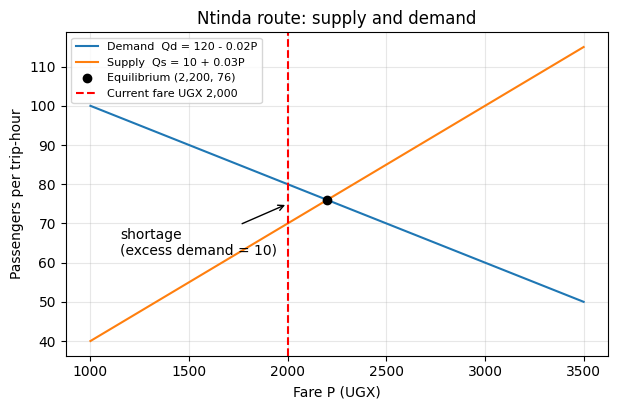

In [3]:
A = np.array([[0.02, 1.0], [-0.03, 1.0]]); b = np.array([120.0, 10.0])
P_star, Q_star = linalg.solve(A, b)
print(f"det(A) = {np.linalg.det(A):.3f}  (non-zero -> unique equilibrium)")
print(f"Equilibrium fare P* = UGX {P_star:,.0f}   quantity Q* = {Q_star:.0f} passengers per trip-hour")
print("class helper agrees:", equilibrium())

pos = market_position(2000)
print(f"\nAt the current fare of UGX 2,000: Qd = {pos['Qd']:.0f}, Qs = {pos['Qs']:.0f}, excess demand = {pos['excess_demand']:.0f}  ->  {pos['state']}")
print(f"Passengers actually carried are limited by supply: min(Qd, Qs) = {min(pos['Qd'], pos['Qs']):.0f} per trip-hour")
rev_now = 2000 * min(pos['Qd'], pos['Qs']); rev_star = P_star * Q_star
print(f"Revenue per trip-hour: now UGX {rev_now:,.0f} vs at equilibrium UGX {rev_star:,.0f} ({rev_star/rev_now - 1:+.1%})")

P = np.linspace(1000, 3500, 200)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(P, 120 - 0.02 * P, label="Demand  Qd = 120 - 0.02P"); ax.plot(P, 10 + 0.03 * P, label="Supply  Qs = 10 + 0.03P")
ax.plot(P_star, Q_star, "ko", label=f"Equilibrium ({P_star:,.0f}, {Q_star:.0f})")
ax.axvline(2000, color="r", ls="--", label="Current fare UGX 2,000")
ax.annotate("shortage\n(excess demand = 10)", (2000, 75), xytext=(1150, 62), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Fare P (UGX)"); ax.set_ylabel("Passengers per trip-hour"); ax.set_title("Ntinda route: supply and demand"); ax.legend(fontsize=8); plt.show()

**Interpretation.** The equilibrium is a fare of **UGX 2,200** with **76 passengers per trip-hour**. The current fare of UGX 2,000 is **below equilibrium**: passengers want 80 seats per trip-hour but taxis
offer only 70, an excess demand of 10 (a shortage: queues, overloaded vehicles, informal surcharges). Raising the fare toward UGX 2,200 would clear the market and, since demand falls
only 0.02 passengers per shilling, would raise revenue by about a fifth (about UGX 140,000 to 167,000 per trip-hour). Caveat: the model is in passengers per trip-hour, while the daily counts above are whole-day totals,
and real fares are also constrained by association agreements and regulation.

## Task 3 - The `Forecaster` hierarchy

In [4]:
y = routes[0].passengers
for m in [MovingAverageForecaster(3), ExponentialSmoothingForecaster(0.5), LinearTrendForecaster()]:
    print(f"{m.name:22s} isinstance Forecaster: {isinstance(m, Forecaster)} | forecast for day 11 (Ntinda): {m.fit(y).predict(1)[0]:.2f}")
print("hand check, 3-day MA of [52, 47, 45] =", (52 + 47 + 45) / 3)

3-day moving average   isinstance Forecaster: True | forecast for day 11 (Ntinda): 48.00
SES (alpha=0.5)        isinstance Forecaster: True | forecast for day 11 (Ntinda): 47.19
Linear trend           isinstance Forecaster: True | forecast for day 11 (Ntinda): 53.67
hand check, 3-day MA of [52, 47, 45] = 48.0


## Task 4 - Rolling-origin backtest (days 4-10) and tuning alpha

For each origin t = 3, ..., 9 the model is fitted on days 1..t only, forecasts day t+1 (never seeing it), and the absolute error is recorded. This mimics real use, unlike an in-sample fit.
That gives **7 out-of-sample forecasts** (days 4-10) per model per route. SES's alpha is tuned by grid search over 0.05, 0.10, ..., 1.00 to minimise the same rolling-origin MAE.

Best alpha per route: {'Kampala-Ntinda': 1.0, 'Kampala-Entebbe': 1.0, 'Kampala-Mukono': 1.0}


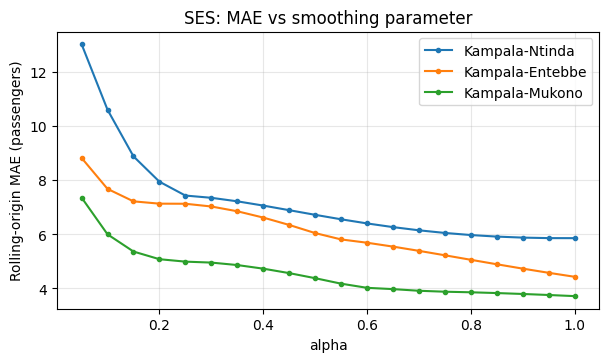

,Kampala-Ntinda,Kampala-Entebbe,Kampala-Mukono
3-day moving average,7.520,7.190,5.330
SES (alpha=1),5.860,4.430,3.710
Linear trend,7.870,7.710,6.390


Best model per route: {'Kampala-Ntinda': 'SES (alpha=1)', 'Kampala-Entebbe': 'SES (alpha=1)', 'Kampala-Mukono': 'SES (alpha=1)'}


In [5]:
alphas = np.round(np.arange(0.05, 1.0001, 0.05), 2)
grid_mae = pd.DataFrame({r.name: [rolling_origin_mae(ExponentialSmoothingForecaster(a), r.passengers, 3) for a in alphas] for r in routes}, index=alphas)
grid_mae.index.name = "alpha"
best_alpha = {r.name: tune_alpha(r.passengers)[0] for r in routes}
print("Best alpha per route:", best_alpha)

fig, ax = plt.subplots(figsize=(7, 3.6))
grid_mae.plot(ax=ax, marker="o", ms=3); ax.set_xlabel("alpha"); ax.set_ylabel("Rolling-origin MAE (passengers)"); ax.set_title("SES: MAE vs smoothing parameter"); plt.show()

mae_table = pd.DataFrame(backtest_table(routes))
display(mae_table.round(2))
print("Best model per route:", mae_table.idxmin().to_dict())

**Result.** SES wins on every route, and the grid search picks the boundary value **alpha = 1.0**, i.e. "tomorrow equals today" (the naive forecast). The 3-day moving average lags
behind whenever demand changes level, and the linear trend extrapolates the mid-period rise (day 6 peak) and then overshoots when demand falls. That the best alpha sits on the edge of the grid tells us there is **no stable
level to smooth** in these 10 days: the series behaves like a random walk with a hump, so the most recent value is the best guess. With only 7 backtest points the tuning is also *optimistic* (alpha is chosen on the same errors used to score it).

## Task 5 - Forecast day-11 revenue with the best model, and actual vs forecast

,best model,forecast pax day 11,fare,forecast revenue (UGX),last actual revenue (UGX)
route,,,,,
Kampala-Ntinda,SES (alpha=1),45.000,"2,000.000","90,000.000","90,000.000"
Kampala-Entebbe,SES (alpha=1),64.000,"5,000.000","320,000.000","320,000.000"
Kampala-Mukono,SES (alpha=1),50.000,"3,000.000","150,000.000","150,000.000"


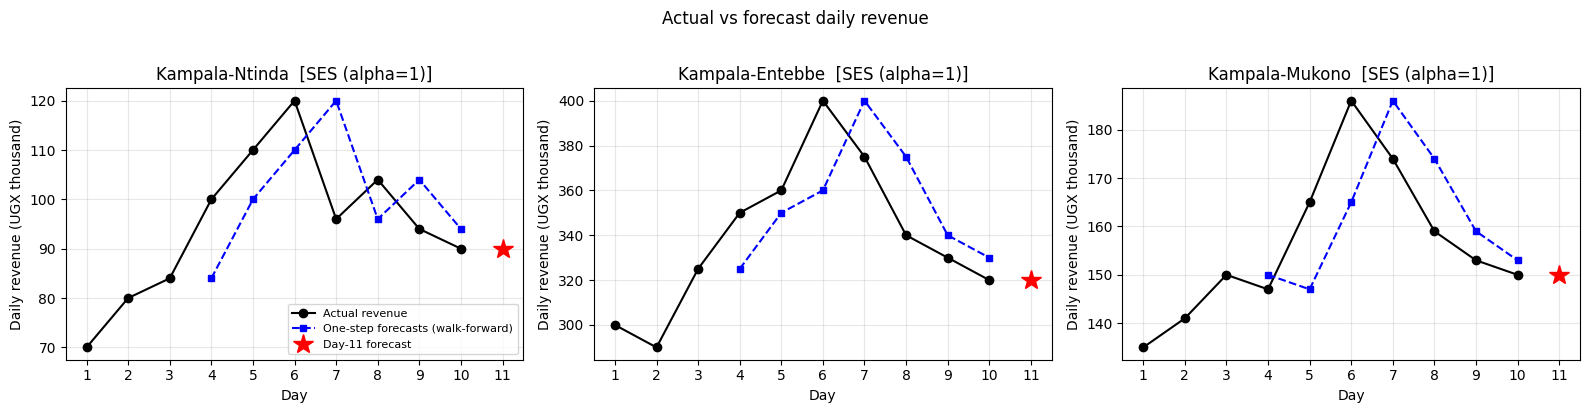

In [6]:
best = {r.name: best_model_for(r) for r in routes}
rows = []
for r in routes:
    m = best[r.name]; f = m.predict(1)[0]
    rows.append({"route": r.name, "best model": m.name, "forecast pax day 11": f, "fare": r.fare, "forecast revenue (UGX)": f * r.fare,
                 "last actual revenue (UGX)": r.daily_revenue()[-1]})
day11 = pd.DataFrame(rows).set_index("route"); display(day11.round(0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, r in zip(axes, routes):
    model = best[r.name]
    preds = []
    for t in range(3, len(r)):
        preds.append(copy.deepcopy(model).fit(r.passengers[:t]).predict(1)[0] * r.fare)
    days = np.arange(1, len(r) + 1)
    ax.plot(days, r.daily_revenue() / 1000, "ko-", label="Actual revenue")
    ax.plot(np.arange(4, 11), np.array(preds) / 1000, "b--s", ms=4, label="One-step forecasts (walk-forward)")
    ax.plot([11], [day11.loc[r.name, "forecast revenue (UGX)"] / 1000], "r*", ms=15, label="Day-11 forecast")
    ax.set_title(f"{r.name}  [{model.name}]"); ax.set_xlabel("Day"); ax.set_ylabel("Daily revenue (UGX thousand)"); ax.set_xticks(range(1, 12))
axes[0].legend(fontsize=8); fig.suptitle("Actual vs forecast daily revenue", y=1.02); plt.tight_layout(); plt.show()

## Task 6 - Fleet planning for day 11

In [7]:
capacity = 8 * 14                                      # passengers per vehicle per day: 8 one-way trips x 14 seats
rows = []
for r in routes:
    f = best[r.name].predict(1)[0]
    rows.append({"route": r.name, "forecast pax": f, "with 15% buffer": f * 1.15, "capacity / vehicle": capacity,
                 "vehicles (raw)": f * 1.15 / capacity, "vehicles deployed (round up)": vehicles_needed(f),
                 "peak day so far": r.passengers.max(), "vehicles for peak day": vehicles_needed(r.passengers.max())})
fleet = pd.DataFrame(rows).set_index("route"); display(fleet.round(2))
print("Total vehicles:", int(fleet["vehicles deployed (round up)"].sum()))

,forecast pax,with 15% buffer,capacity / vehicle,vehicles (raw),vehicles deployed (round up),peak day so far,vehicles for peak day
route,,,,,,,
Kampala-Ntinda,45.000,51.750,112,0.460,1,60.000,1
Kampala-Entebbe,64.000,73.600,112,0.660,1,80.000,1
Kampala-Mukono,50.000,57.500,112,0.510,1,62.000,1


Total vehicles: 3


One vehicle offers 8 x 14 = **112 seat-trips a day**. With the 15 % safety buffer, forecasts of 45, 64 and 50 passengers need 0.46, 0.66 and 0.51 of a vehicle. We **round up** because a fraction of a vehicle
cannot be deployed and running short costs more than a part-empty taxi, so each route gets **1 vehicle** (3 in total). Even each route's busiest day (up to 80 passengers, 92 with the buffer) fits in one vehicle.
The counts are therefore small relative to the stated fleet capacity. If they are really counts *per vehicle* or per hour, the plan must be rescaled with `vehicles_needed`.

## Extension - 60 simulated days with a weekly pattern: seasonal-naive vs moving average

{'Mon': 50.0, 'Tue': 47.9, 'Wed': 50.2, 'Thu': 52.0, 'Fri': 67.5, 'Sat': 54.8, 'Sun': 33.6}


,MAE (passengers)
Seasonal naive (m=7),2.650
Linear trend,6.500
SES (alpha=0.5),7.930
3-day moving average,8.080


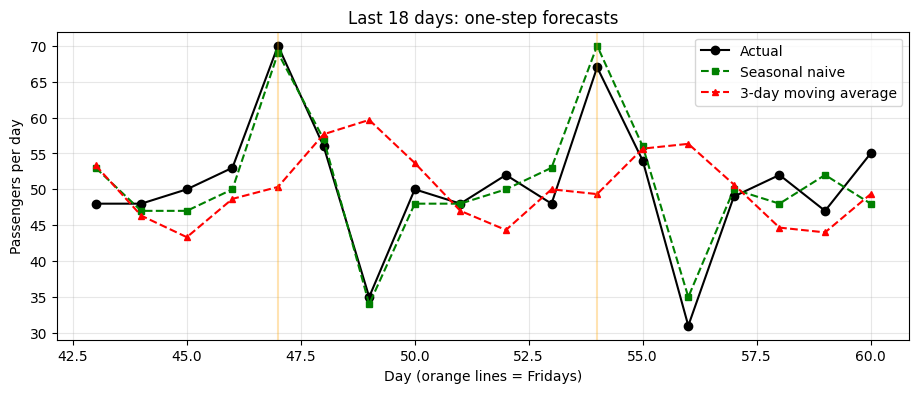

In [8]:
y60 = simulate_weekly_series(days=60, base=50, noise=3, seed=SEED)        # day 1 = Monday; Fridays busy, Sundays quiet
dow = np.array(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
print(pd.Series(y60).groupby(np.arange(60) % 7).mean().rename(dict(enumerate(map(str, dow)))).round(1).to_dict())

models = {"Seasonal naive (m=7)": SeasonalNaiveForecaster(7), "3-day moving average": MovingAverageForecaster(3),
          "SES (alpha=0.5)": ExponentialSmoothingForecaster(0.5), "Linear trend": LinearTrendForecaster()}
res = pd.Series({k: rolling_origin_mae(m, y60, first_origin=14) for k, m in models.items()}, name="MAE (passengers)").sort_values()
display(res.to_frame().round(2))

sn = [copy.deepcopy(models["Seasonal naive (m=7)"]).fit(y60[:t]).predict(1)[0] for t in range(42, 60)]
ma = [copy.deepcopy(models["3-day moving average"]).fit(y60[:t]).predict(1)[0] for t in range(42, 60)]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(43, 61), y60[42:], "ko-", label="Actual"); ax.plot(range(43, 61), sn, "g--s", ms=4, label="Seasonal naive")
ax.plot(range(43, 61), ma, "r--^", ms=4, label="3-day moving average")
for d in range(43, 61):
    if (d - 1) % 7 == 4: ax.axvline(d, color="orange", alpha=0.3)
ax.set_xlabel("Day (orange lines = Fridays)"); ax.set_ylabel("Passengers per day"); ax.set_title("Last 18 days: one-step forecasts"); ax.legend(); plt.show()

The seasonal-naive forecaster (same weekday last week) is about three times more accurate than the moving average. Averaging the last three days *smears* the Friday spike and
Sunday dip: it under-forecasts Fridays and over-forecasts Sundays every week. The seasonal-naive method reproduces the weekly cycle and its error is
essentially the day-to-day noise (roughly 3 passengers, plus the noise of last week's value). On a series without weekly structure (as in the original 10 days) this advantage disappears,
so the method should be chosen by backtesting, not habit.

## Findings & Limitations

## Findings & Limitations

**Findings.** Solving the Ntinda demand and supply equations gives an equilibrium fare of UGX 2,200 and 76 passengers per trip-hour. The current UGX 2,000 fare is below
it, creating an excess demand of 10 passengers per trip-hour; a modest fare rise would ease crowding and, by this model, raise revenue by about 19 %. In walk-forward
backtesting over days 4-10, simple exponential smoothing beat the 3-day moving average and the linear trend on all three routes (for Ntinda, MAE 5.9 against 7.5 and 7.9 passengers), and the tuned alpha was 1.0, meaning the
latest observation is the best predictor. Day-11 forecasts are 45, 64 and 50 passengers (UGX 90,000, 320,000 and 150,000). With a 15 % buffer each route needs one vehicle.
In the 60-day simulation with a weekly cycle, seasonal-naive achieved an MAE of about 2.7 passengers against 8.1 for the moving average, showing that the right model depends on the
structure in the data.

**Limitations.** Ten days is far too short to detect weekly patterns or to tune alpha reliably: the backtest has only seven points and alpha is chosen on
the same errors it is scored on. The supply-demand equations are linear assumptions in passengers per trip-hour and cannot be compared directly with daily counts. Fares are treated as fixed, so the model
ignores elasticity, competitor operators, traffic, rain and public holidays. Fleet size ignores peak-hour concentration, breakdowns and driver hours, and the small counts relative to vehicle capacity
suggest the data may not be route totals. The extension series is synthetic, so the seasonal advantage is built in by construction.